# 05 - LSTM classifier for point and contextual anomalies (Day 11)

**Question:** given the last 30 readings of a sensor, can a *supervised* sequence model say whether the
reading that just arrived is **normal**, a **point** anomaly (a spike) or a **contextual** anomaly (a
plausible value at the wrong time), and are its probabilities trustworthy enough to stack in the Day 12
ensemble?

Model (`src/models/lstm_classifier.py`): 2-layer bidirectional LSTM (hidden 64) -> additive attention over
all 30 time steps -> `Linear(128,64) -> ReLU -> Dropout(0.3) -> Linear(64,3)`. Trained with a
class-weighted cross-entropy, AdamW (`weight_decay=1e-4`), cosine annealing and early stopping on the
validation macro-F1, then temperature-scaled on the validation set.

Design choices worth knowing before reading the numbers:

* A window is labelled with the class of its **newest** row. Windows that end in a *collective* (drift)
  anomaly are dropped - that is the Day 10 autoencoder's job, and labelling them "normal" would teach the
  model that a drifting sensor is fine.
* The split is **block-wise** (whole 5-minute blocks per sensor, stratified on the rarest class in a
  block) with an embargo on windows that straddle a block edge, because neighbouring windows share 29 of
  30 rows. A plain random split would leak near-copies into the test set.
* **SMOTE and class weights are combined, not stacked**: SMOTE lifts the rare classes on the training
  split only, and the loss weights are computed from the post-SMOTE class frequencies. Validation and
  test keep the natural class distribution.

In [1]:
import sys, os, time, logging, warnings
from pathlib import Path
from datetime import datetime, UTC

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
logging.getLogger("src").setLevel(logging.WARNING)
warnings.filterwarnings("ignore")

from IPython.display import Markdown, display
from src.models.lstm_classifier import (
    DatasetBuilder, TemperatureScaler, evaluate_predictions, predict_logits, reliability_bins,
    train_classifier,
)
from src.utils.config import LSTMClassifierConfig

sns.set_theme(style="whitegrid", context="notebook")
SEED = 7
CLASSES = ("normal", "point", "contextual")
COLORS = {"normal": "#6b7280", "point": "#d62728", "contextual": "#ff7f0e"}
torch.set_num_threads(max(1, os.cpu_count() or 1))
print("torch", torch.__version__, "| device:", "cuda" if torch.cuda.is_available() else "cpu")

torch 2.15.0+cu132 | device: cpu


## 1. Data

12 simulated hours, starting at 19:00 so the stream contains business hours *and* the 00:00-05:00 window in
which the simulator injects contextual anomalies. Features come from the production path (simulator ->
windowed aggregator -> `FeatureEngineer`), so there is no train/serve skew. The clock features are kept:
a contextual anomaly is defined by the hour, so the model must be able to see it.

In [2]:
from src.models.offline_dataset import simulate_labeled_features

t0 = time.time()
rows = simulate_labeled_features(12 * 3600, start_time=datetime(2026, 11, 20, 19, 0, tzinfo=UTC), seed=SEED)["warehouse"]
print(f"{len(rows):,} warehouse events, {len(rows.feature_names)} features, {len(set(rows.entity_ids))} sensors "
      f"({time.time()-t0:.0f}s)")
print("row labels:", rows.type_counts())

518,400 warehouse events, 30 features, 12 sensors (48s)
row labels: {'collective': 2622, 'contextual': 10085, 'normal': 495612, 'point': 10081}


In [3]:
# stride 10 keeps the notebook fast; the module default (5) gives twice the windows
builder = DatasetBuilder(stride=10, smote_ratio=0.3, seed=SEED)
data = builder.build(rows)

summary = pd.DataFrame(data.summary()).T[list(CLASSES)]
summary["total"] = summary.sum(axis=1)
display(summary)
print("class weights (from the post-SMOTE training labels):", dict(zip(CLASSES, data.class_weights.round(2))))
print({k: data.info[k] for k in ("n_windows", "n_collective_dropped", "n_straddling_dropped", "n_groups", "n_synthetic")})

share = pd.DataFrame({k: v / v.sum() for k, v in
                      {"train (real)": data.train_real.class_counts(3), "validation": data.val.class_counts(3),
                       "test": data.test.class_counts(3)}.items()}, index=CLASSES).T
display(share.style.format("{:.2%}"))

,normal,point,contextual,total
train_real,31666,654,654,32974
train_smote,31666,9500,9500,50666
val,6805,146,125,7076
test,6758,145,159,7062


class weights (from the post-SMOTE training labels): {'normal': np.float64(0.53), 'point': np.float64(1.78), 'contextual': np.float64(1.78)}
{'n_windows': 50844, 'n_collective_dropped': 252, 'n_straddling_dropped': 3480, 'n_groups': 1764, 'n_synthetic': 17692}


,normal,point,contextual
train (real),96.03%,1.98%,1.98%
validation,96.17%,2.06%,1.77%
test,95.70%,2.05%,2.25%


Validation and test keep the natural prevalence (about 96% normal), so every metric below describes what the
detector would see in deployment. Only the training split is oversampled.

## 2. Training

In [4]:
cfg = LSTMClassifierConfig(max_epochs=15, early_stopping_patience=8, batch_size=128)   # spec: 50 epochs; shortened for the notebook
t0 = time.time()
# num_workers=0: the data is already in memory and worker processes break in Jupyter on Windows
detector, history = train_classifier(data, cfg, log_dir="runs/lstm_classifier", run_name="notebook05",
                                     num_workers=0, seed=SEED)
print(f"trained {history.epochs_run} epochs in {time.time()-t0:.0f}s; best epoch {history.best_epoch} "
      f"(val macro-F1 {history.best_score:.3f}); stopped early: {history.stopped_early}")

trained 15 epochs in 242s; best epoch 11 (val macro-F1 0.806); stopped early: False


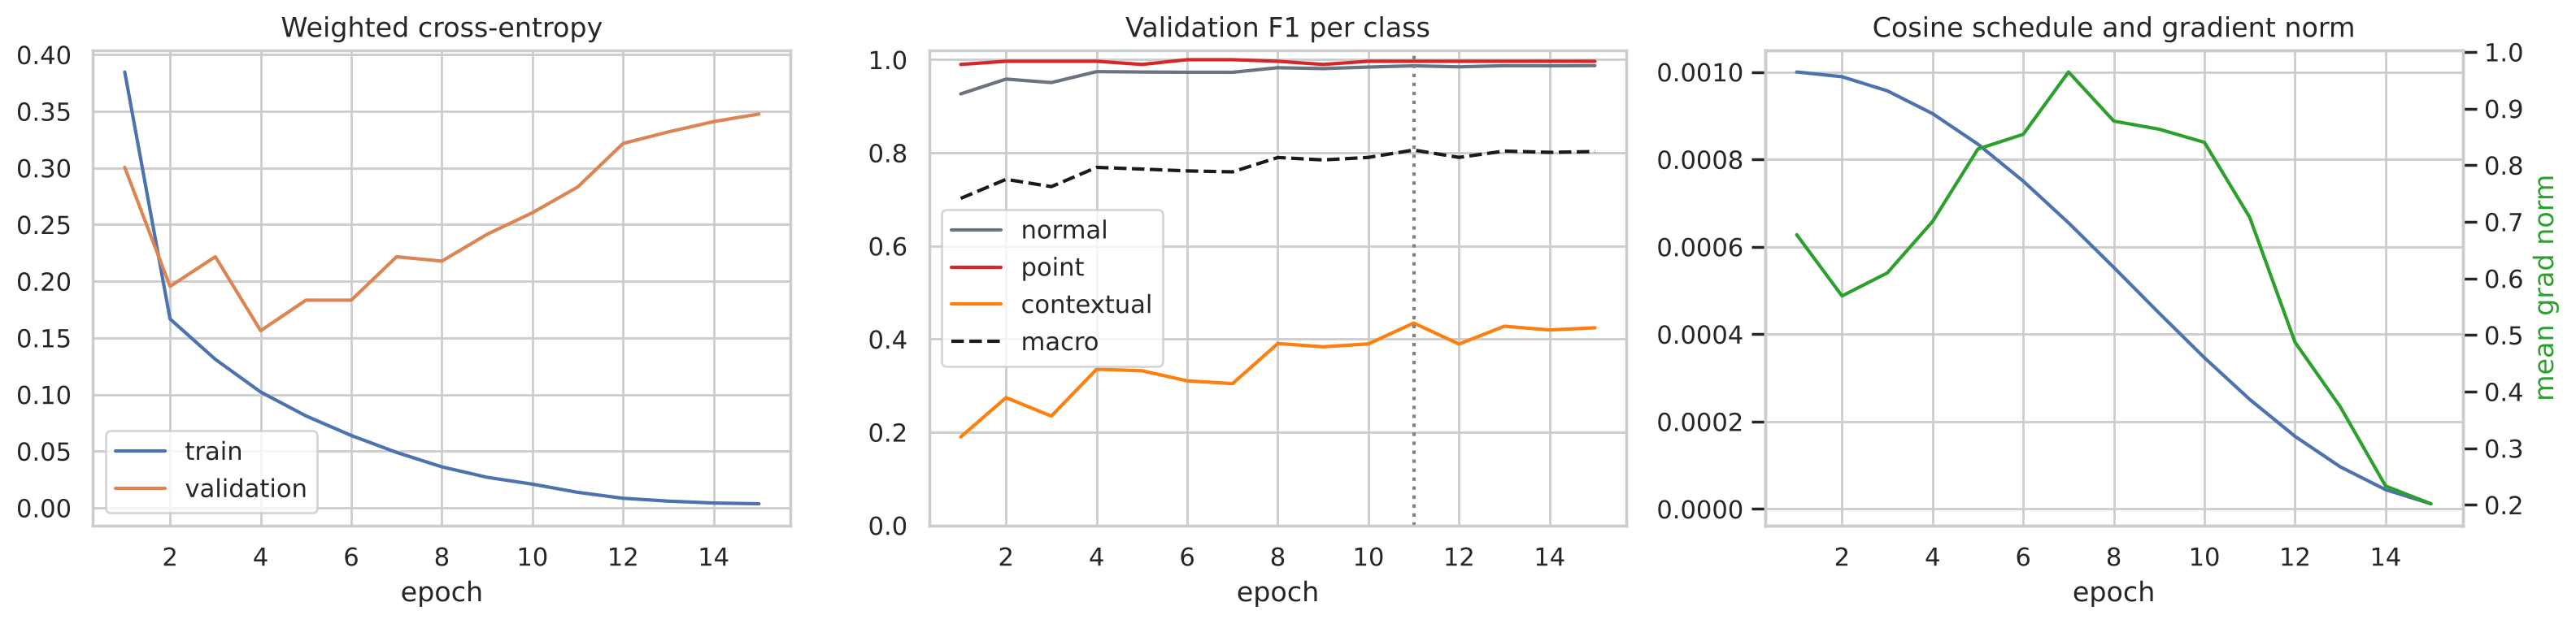

In [5]:
ep = np.arange(1, history.epochs_run + 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(ep, history.train_loss, label="train"); ax[0].plot(ep, history.val_loss, label="validation")
ax[0].set(title="Weighted cross-entropy", xlabel="epoch"); ax[0].legend()
for k, name in enumerate(CLASSES):
    ax[1].plot(ep, [f[k] for f in history.val_f1], label=name, color=COLORS[name])
ax[1].plot(ep, history.val_macro_f1, "k--", label="macro")
ax[1].axvline(history.best_epoch, color="grey", ls=":"); ax[1].set(title="Validation F1 per class", xlabel="epoch", ylim=(0, 1.02)); ax[1].legend()
ax[2].plot(ep, history.learning_rate, label="learning rate"); ax[2].set(title="Cosine schedule and gradient norm", xlabel="epoch")
ax2 = ax[2].twinx(); ax2.plot(ep, history.gradient_norm, color="tab:green"); ax2.set_ylabel("mean grad norm", color="tab:green"); ax2.grid(False)
plt.tight_layout(); plt.show()

## 3. Calibration

Temperature scaling divides the logits by one scalar `T` fitted on the validation set. It never changes the
predicted class, only how confident the probabilities are. `T > 1` means the network was over-confident.

fitted temperature T = 2.496


,T = 1 (raw),T = 2.50
test NLL,0.1508,0.0818
test ECE,0.0210,0.0050


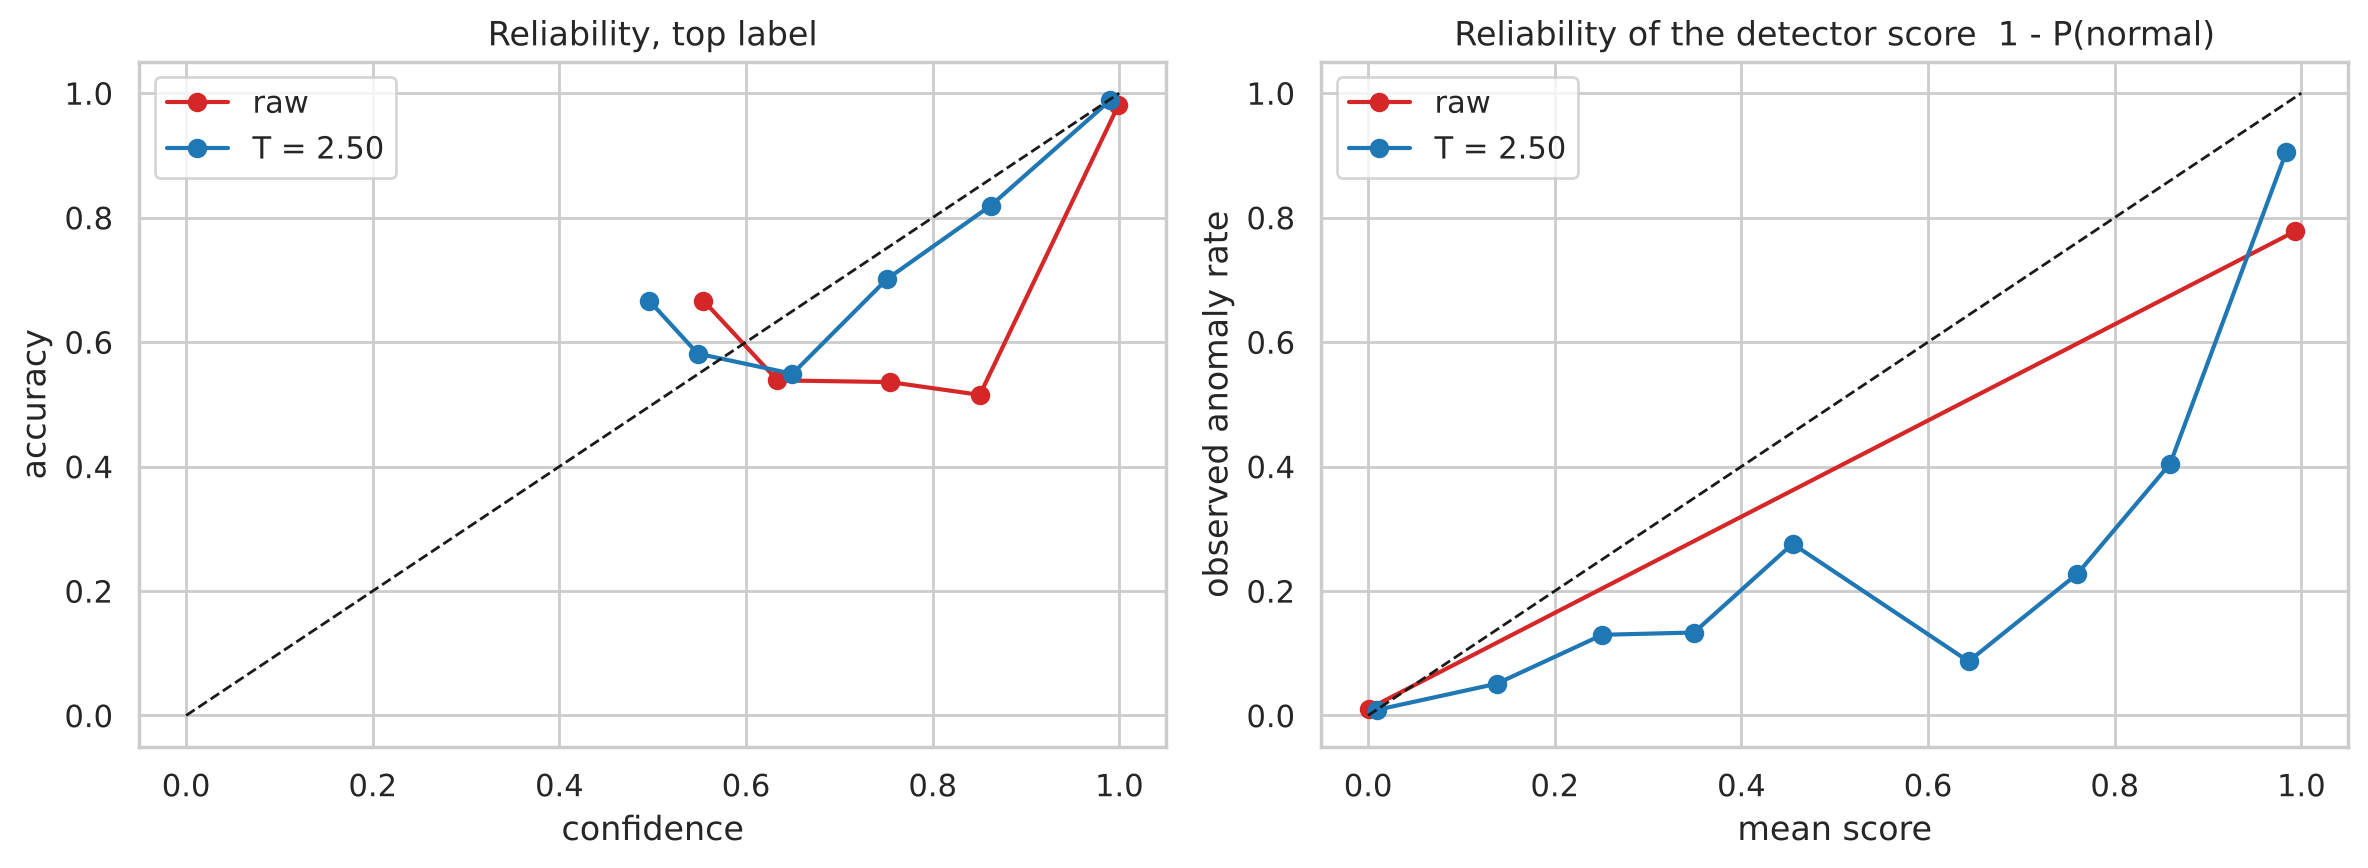

In [6]:
val_logits, _ = predict_logits(detector.model, data.val.x)
test_logits, test_attn = predict_logits(detector.model, data.test.x)
T = detector.temperature.temperature
raw = TemperatureScaler(1.0)

rep_raw = evaluate_predictions(data.test.y, raw.scale(test_logits), CLASSES)
rep = evaluate_predictions(data.test.y, detector.temperature.scale(test_logits), CLASSES)
print(f"fitted temperature T = {T:.3f}")
display(pd.DataFrame({"T = 1 (raw)": [rep_raw.nll, rep_raw.ece], f"T = {T:.2f}": [rep.nll, rep.ece]}, index=["test NLL", "test ECE"]).round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for scaler, label, color in ((raw, "raw", "tab:red"), (detector.temperature, f"T = {T:.2f}", "tab:blue")):
    p = scaler.scale(test_logits)
    conf, acc, cnt = reliability_bins(p.max(1), p.argmax(1) == data.test.y, 10)
    ok = cnt > 0
    ax[0].plot(conf[ok], acc[ok], "o-", label=label, color=color)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(title="Reliability, top label", xlabel="confidence", ylabel="accuracy"); ax[0].legend()

# P(anomaly) = 1 - P(normal): the detector's score
anom = data.test.y > 0
for scaler, label, color in ((raw, "raw", "tab:red"), (detector.temperature, f"T = {T:.2f}", "tab:blue")):
    s = 1 - scaler.scale(test_logits)[:, 0]
    bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(s, bins[1:-1], right=True), 0, 9)
    xs = [s[idx == b].mean() for b in range(10) if (idx == b).sum() >= 20]
    ys = [anom[idx == b].mean() for b in range(10) if (idx == b).sum() >= 20]
    ax[1].plot(xs, ys, "o-", label=label, color=color)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(title="Reliability of the detector score  1 - P(normal)", xlabel="mean score", ylabel="observed anomaly rate"); ax[1].legend()
plt.tight_layout(); plt.show()

The right panel is the one that matters for stacking. Training used rebalanced classes, so the score can be
biased relative to the natural anomaly rate even after scaling: **temperature scaling repairs over-confidence,
not a shifted base rate.** Read the gap to the diagonal in the right panel for how large that bias is here. The Day 12 meta-learner should therefore treat this score as a ranking feature and be
trained on natural-prevalence data (which it will be: it is fit on held-out labelled data).

## 4. Test-set evaluation (natural class distribution, argmax decision)

,precision,recall,F1,support,ROC-AUC (OvR),avg precision (OvR)
normal,0.987,0.987,0.987,6758,0.952,0.997
point,1.000,0.993,0.997,145,1.000,1.000
contextual,0.452,0.472,0.462,159,0.924,0.473


accuracy 0.975 | macro-F1 0.815 | weighted-F1 0.975 | any-anomaly ROC-AUC 0.952 | any-anomaly AP 0.791


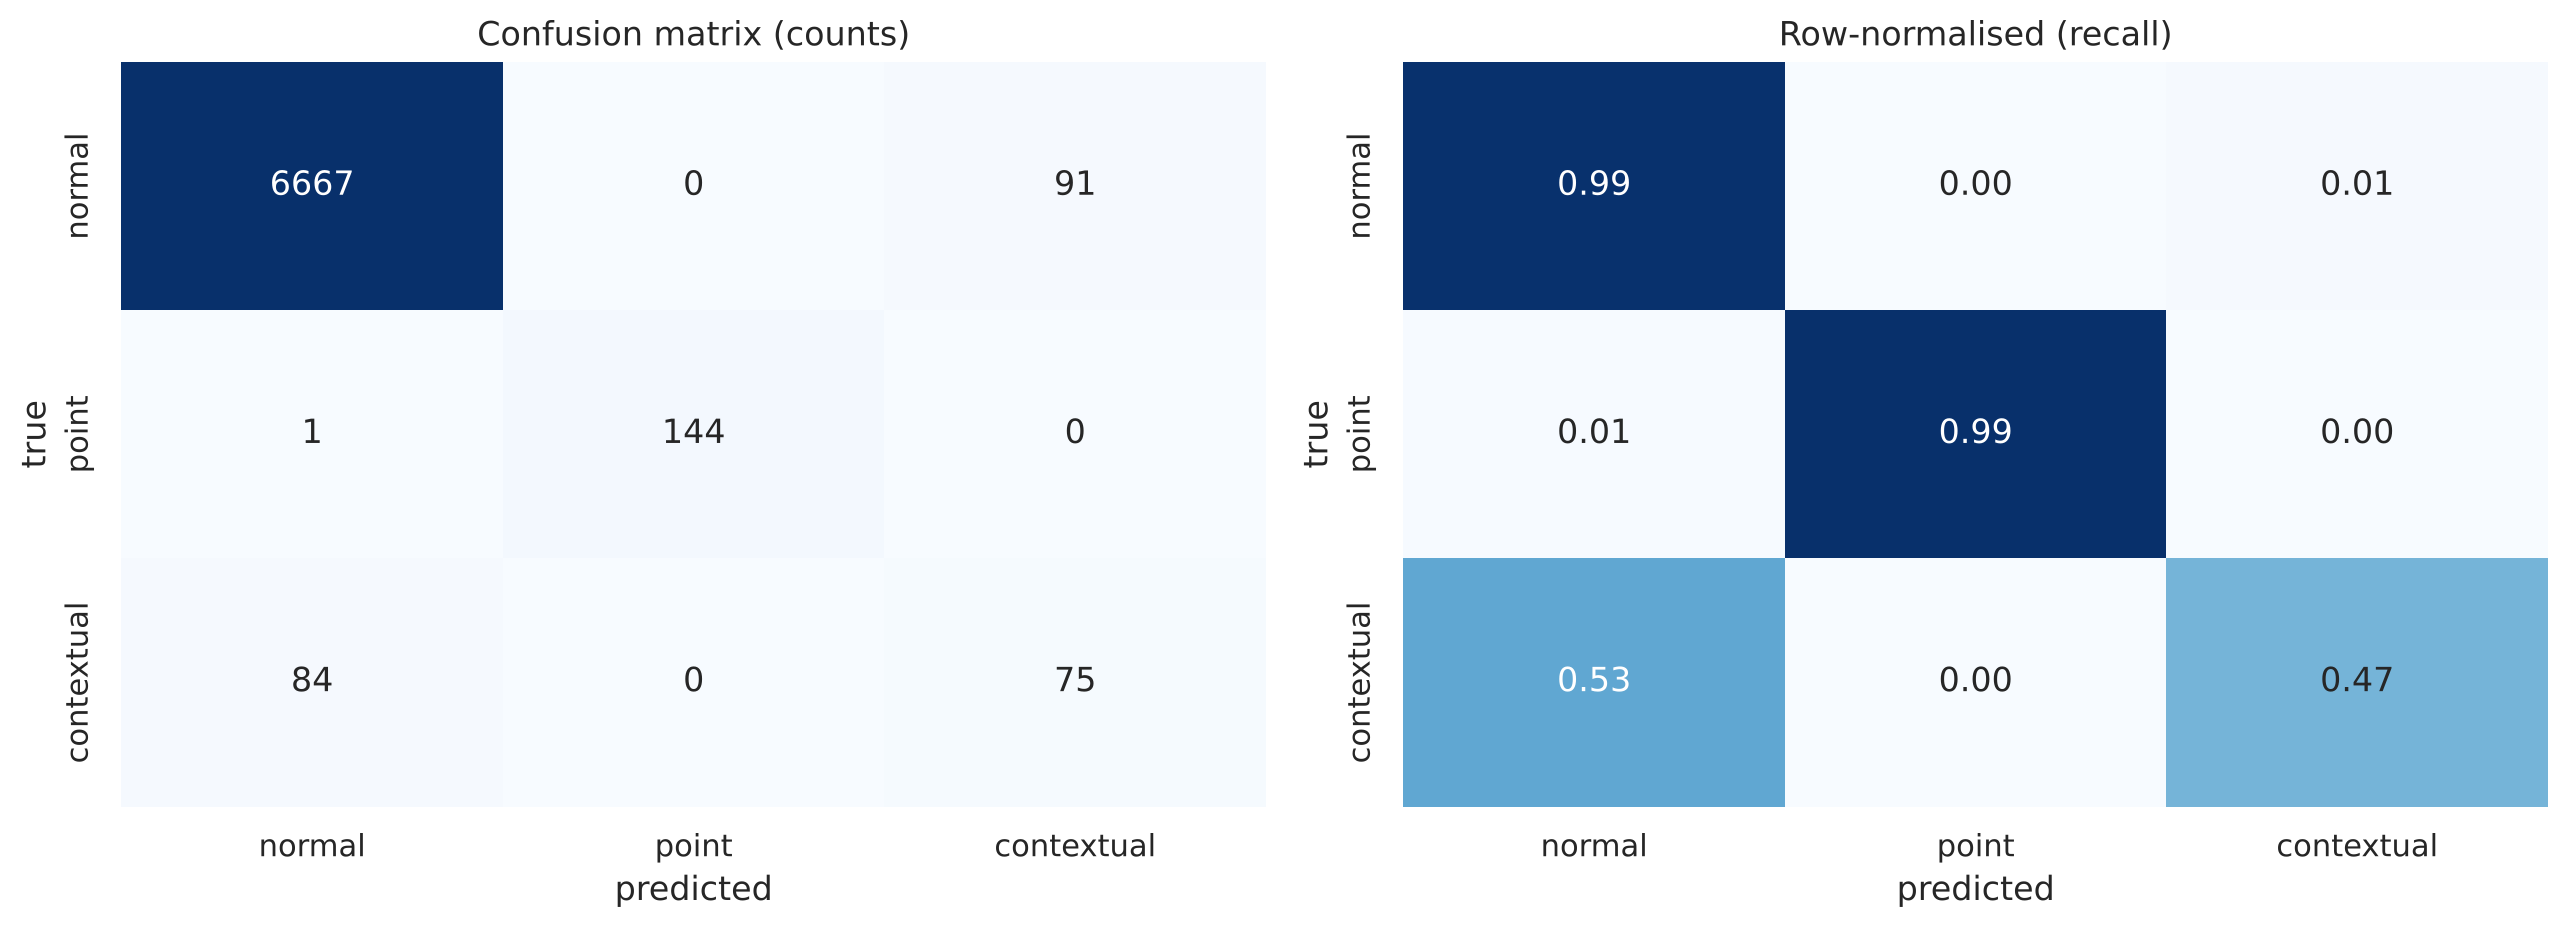

In [7]:
tab = pd.DataFrame({"precision": rep.precision, "recall": rep.recall, "F1": rep.f1, "support": rep.support,
                    "ROC-AUC (OvR)": [rep.roc_auc[c] for c in CLASSES],
                    "avg precision (OvR)": [rep.average_precision[c] for c in CLASSES]}, index=CLASSES)
display(tab.round(3))
print(f"accuracy {rep.accuracy:.3f} | macro-F1 {rep.macro_f1:.3f} | weighted-F1 {rep.weighted_f1:.3f} | "
      f"any-anomaly ROC-AUC {rep.anomaly_roc_auc:.3f} | any-anomaly AP {rep.anomaly_average_precision:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
cm = rep.confusion
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
ax[0].set(title="Confusion matrix (counts)", xlabel="predicted", ylabel="true")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
ax[1].set(title="Row-normalised (recall)", xlabel="predicted", ylabel="true")
plt.tight_layout(); plt.show()

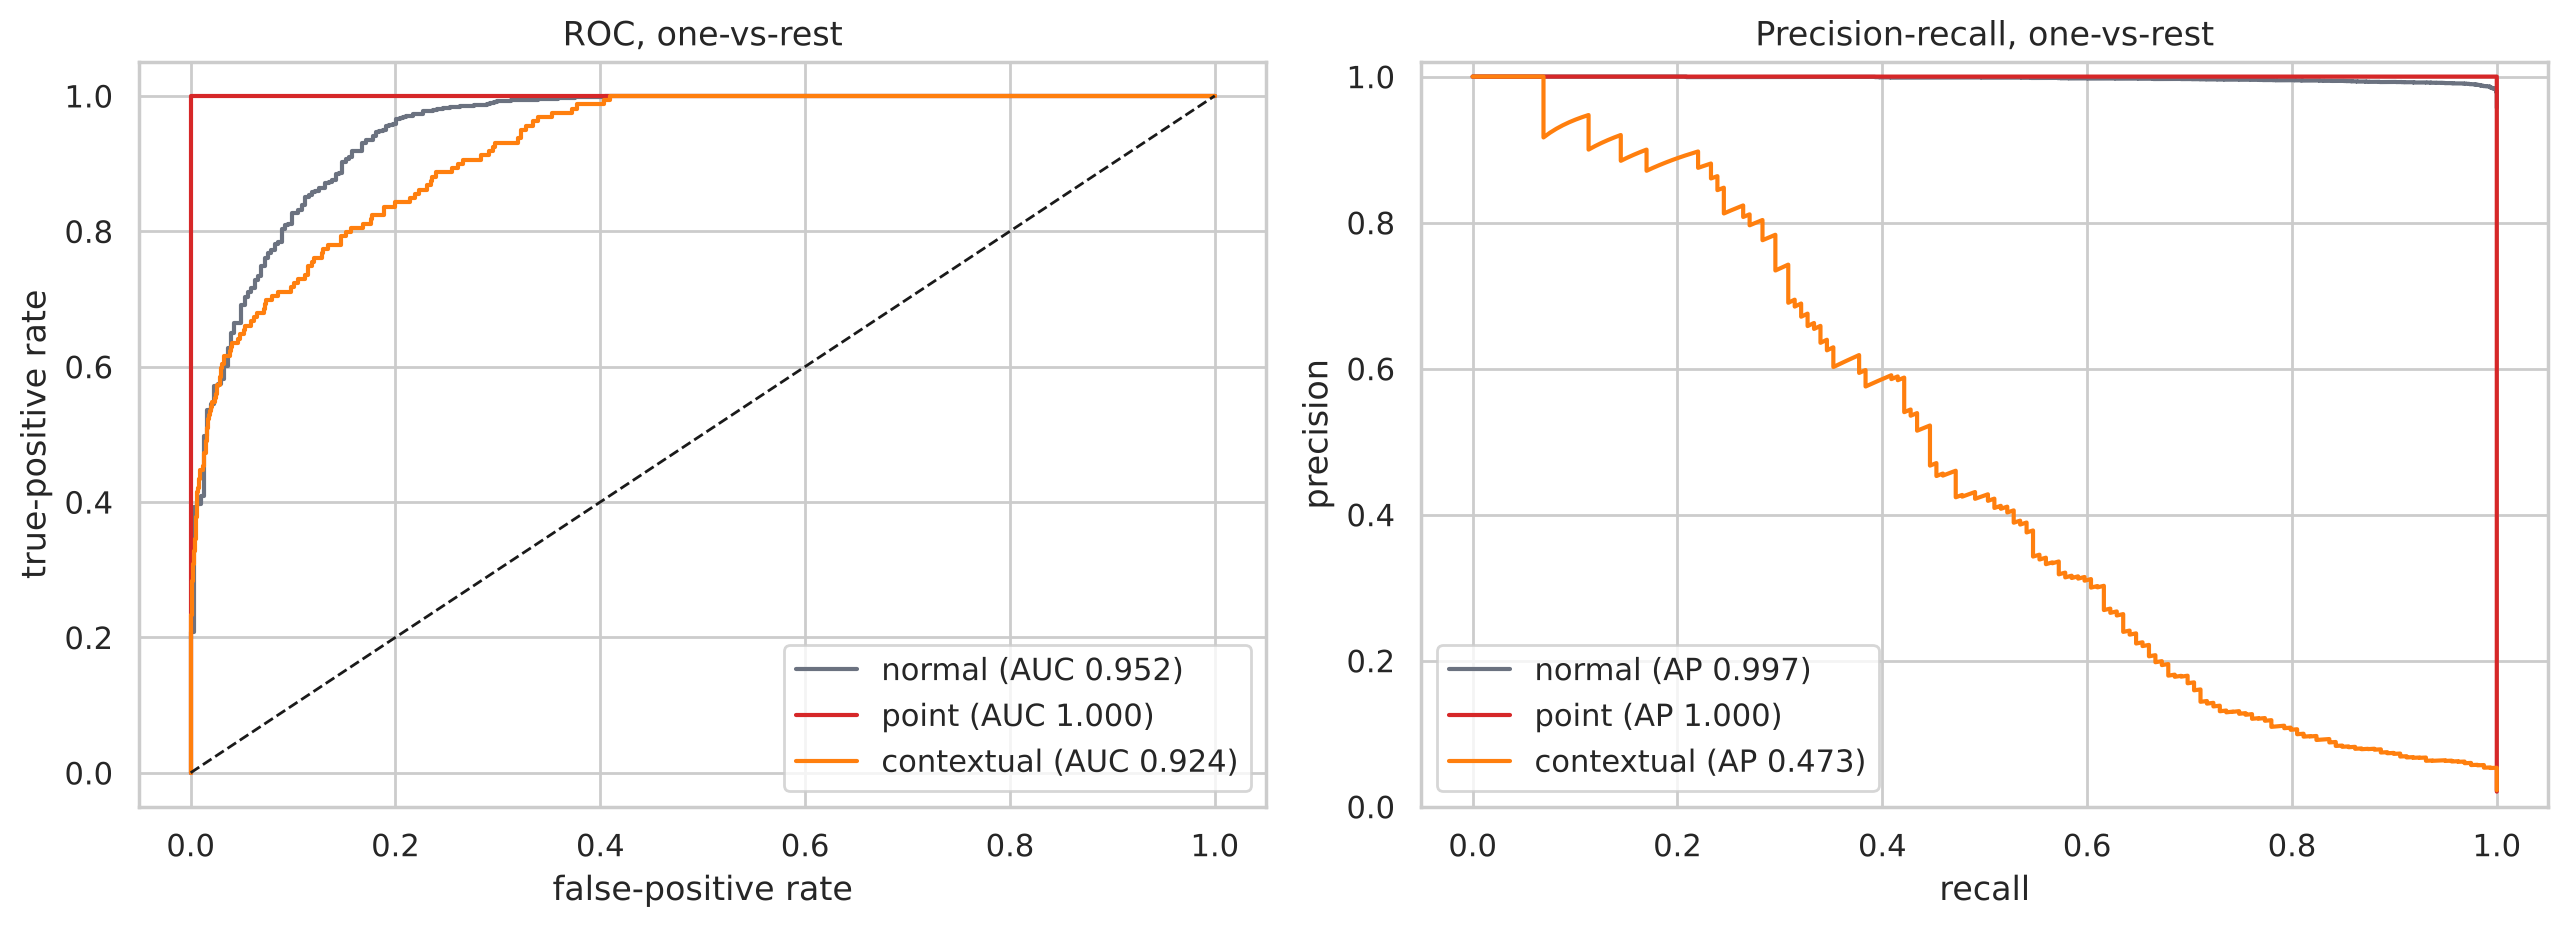

In [8]:
probs = detector.temperature.scale(test_logits)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for k, name in enumerate(CLASSES):
    pos = data.test.y == k
    if pos.all() or not pos.any():
        continue
    fpr, tpr, _ = roc_curve(pos, probs[:, k]); ax[0].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {rep.roc_auc[name]:.3f})")
    pr, rc, _ = precision_recall_curve(pos, probs[:, k]); ax[1].plot(rc, pr, color=COLORS[name], label=f"{name} (AP {rep.average_precision[name]:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(title="ROC, one-vs-rest", xlabel="false-positive rate", ylabel="true-positive rate"); ax[0].legend()
ax[1].set(title="Precision-recall, one-vs-rest", xlabel="recall", ylabel="precision", ylim=(0, 1.02)); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Where do the errors come from?

If contextual precision is low, is the model confused at random or is something systematic going on? The
label of a window is the class of its newest row, but the aggregated features (1-, 5- and 15-minute windows)
keep "remembering" an anomaly for a while after it ended. Windows that are labelled normal because the
anomaly just finished are therefore genuinely ambiguous. Below: for every test window that is truly normal,
how long ago did *any* anomaly end on the same sensor, split by whether the model flagged it?

In [9]:
ent = rows.entity_ids.astype(str); ts = rows.timestamps; anomalous = rows.y
last_anom = {}
for e in np.unique(ent):
    m = (ent == e) & anomalous
    last_anom[e] = np.sort(ts[m])

def since_last_anomaly(e, t):
    arr = last_anom[e]; i = np.searchsorted(arr, t, side="right") - 1
    return t - arr[i] if i >= 0 else np.inf

y, pred = data.test.y, probs.argmax(1)
normal = np.flatnonzero(y == 0)
gap = np.array([since_last_anomaly(str(data.test.entity_ids[i]), data.test.end_timestamps[i]) for i in normal])
flagged = pred[normal] > 0
bins = [0, 30, 60, 120, 300, 900, np.inf]; labels = ["<30s", "30-60s", "1-2min", "2-5min", "5-15min", ">15min"]
cat = pd.cut(gap, bins=bins, labels=labels, right=False)
err = pd.DataFrame({"gap": cat, "flagged": flagged}).groupby("gap", observed=False)["flagged"].agg(["mean", "sum", "count"])
err.columns = ["false-alarm rate", "false alarms", "normal windows"]
display(err.round(3))
fa_recent = flagged[gap < 300].sum() / max(flagged.sum(), 1)
print(f"{fa_recent:.0%} of all false alarms occur within 5 minutes of a real anomaly on the same sensor")

,false-alarm rate,false alarms,normal windows
gap,,,
<30s,0.019,33,1699
30-60s,0.022,28,1279
1-2min,0.013,20,1540
2-5min,0.005,9,1699
5-15min,0.002,1,533
>15min,0.000,0,8


99% of all false alarms occur within 5 minutes of a real anomaly on the same sensor


## 6. Choosing an operating point for the detector score

The detector's `score` is `1 - P(normal)`; `decision_threshold` (default 0.5) turns it into `is_anomaly`.
Argmax and 0.5 are not necessarily the best trade-off for an alerting system: the sweep below shows the
precision/recall each threshold gives for "any anomaly".

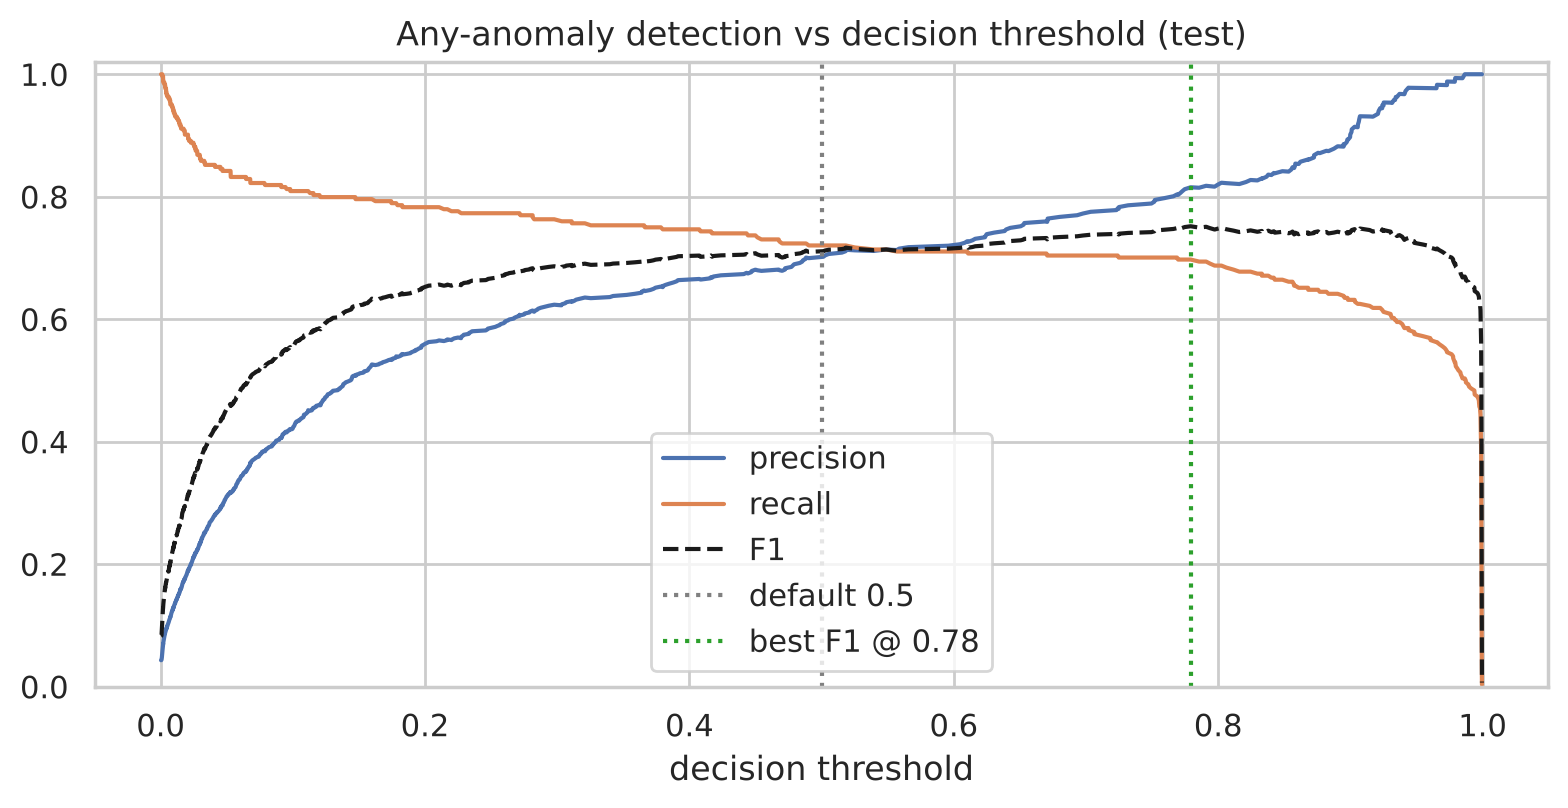

threshold 0.50: precision 0.702, recall 0.720
threshold 0.78: precision 0.815, recall 0.697
NOTE: the best threshold is read off the test set here for illustration; choose it on validation in production.


In [10]:
s = 1 - probs[:, 0]
prec, rec, thr = precision_recall_curve(data.test.y > 0, s)
f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
best = f1[:-1].argmax()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(thr, prec[:-1], label="precision"); ax.plot(thr, rec[:-1], label="recall"); ax.plot(thr, f1[:-1], "k--", label="F1")
ax.axvline(0.5, color="grey", ls=":", label="default 0.5"); ax.axvline(thr[best], color="tab:green", ls=":", label=f"best F1 @ {thr[best]:.2f}")
ax.set(title="Any-anomaly detection vs decision threshold (test)", xlabel="decision threshold", ylim=(0, 1.02)); ax.legend()
plt.tight_layout(); plt.show()
at = lambda t: (np.sum((s >= t) & (data.test.y > 0)) / np.sum(s >= t), np.sum((s >= t) & (data.test.y > 0)) / np.sum(data.test.y > 0))
for t in (0.5, thr[best]):
    p_, r_ = at(t); print(f"threshold {t:.2f}: precision {p_:.3f}, recall {r_:.3f}")
print("NOTE: the best threshold is read off the test set here for illustration; choose it on validation in production.")

## 7. What does the attention look at?

The attention weights say which of the 30 time steps drove the decision (`details["attention_weights"]` on
every `AnomalyScore`). Left: a correctly detected point anomaly; right: a correctly detected contextual one.
Heatmaps show the standardised features; the bar above shows the attention.

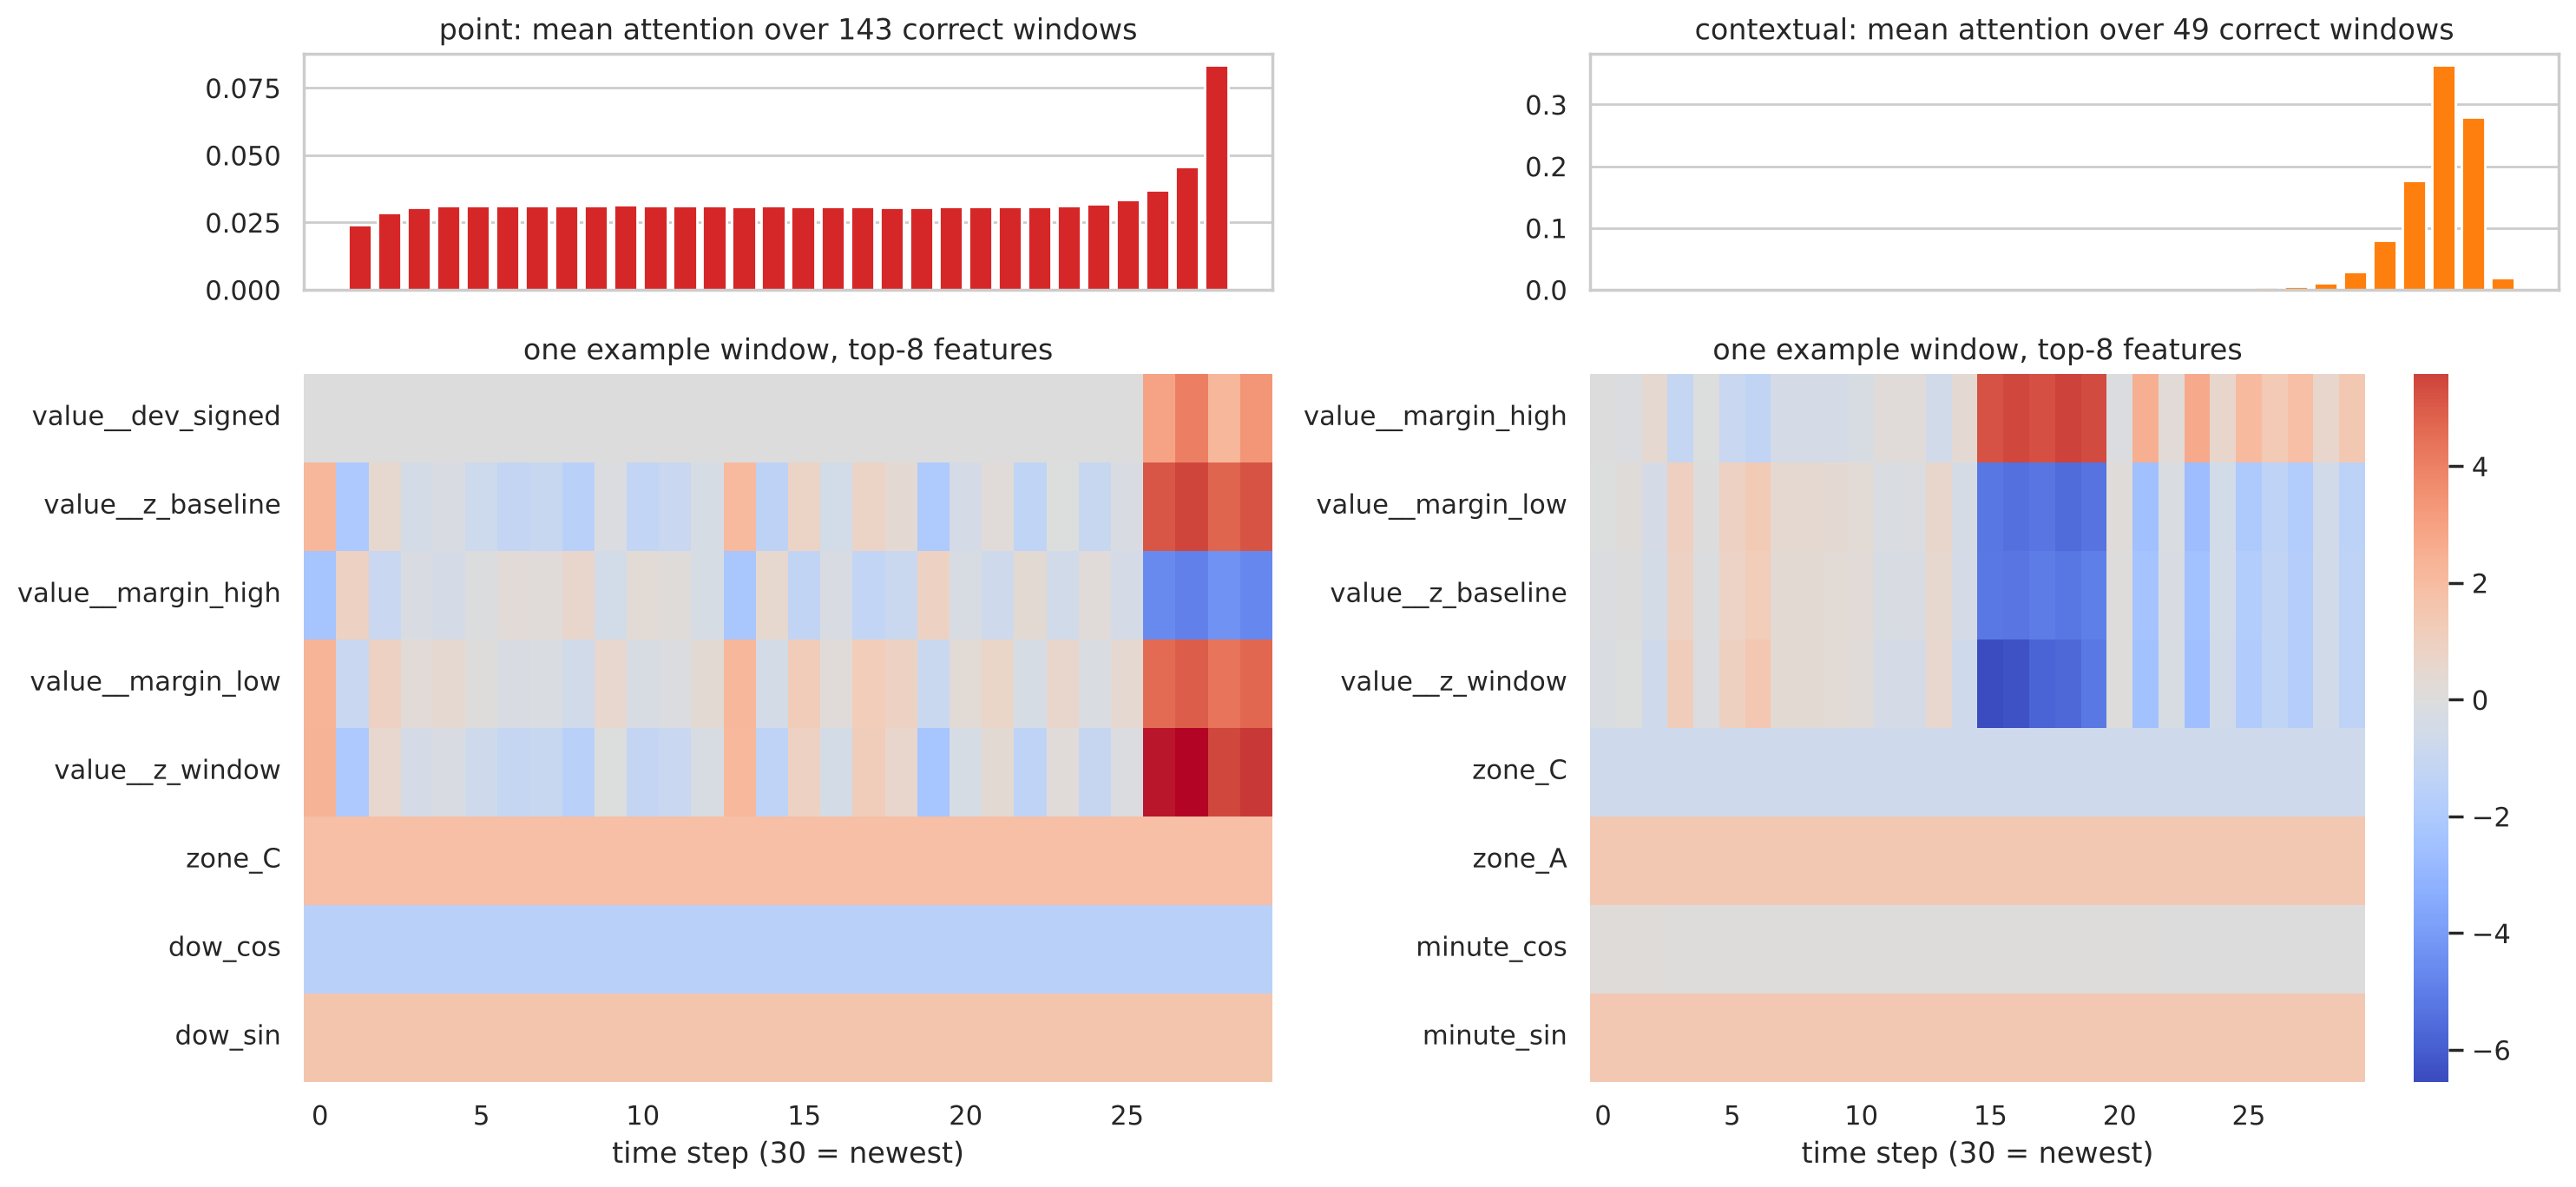

attention mass on the newest 5 of 30 steps (uniform would be 0.167): {'point': 0.232, 'contextual': 0.919}


In [11]:
def correct(k):
    idx = np.flatnonzero((data.test.y == k) & (pred == k) & (probs[:, k] > 0.9))
    return idx

fig, axes = plt.subplots(2, 2, figsize=(15, 7), gridspec_kw={"height_ratios": [1, 3]})
for col, k in enumerate((1, 2)):
    idx = correct(k)
    if not len(idx):
        continue
    avg = test_attn[idx].mean(0)
    axes[0, col].bar(range(30), avg, color=COLORS[CLASSES[k]]); axes[0, col].set(title=f"{CLASSES[k]}: mean attention over {len(idx)} correct windows", xticks=[])
    # features that move most at the newest steps in these windows
    z = np.abs(data.test.x[idx][:, -5:, :]).mean((0, 1)); top = np.argsort(-z)[:8]
    sns.heatmap(data.test.x[idx[0]][:, top].T, ax=axes[1, col], cmap="coolwarm", center=0, cbar=col == 1,
                yticklabels=[data.feature_names[j] for j in top], xticklabels=5)
    axes[1, col].set(xlabel="time step (30 = newest)", title=f"one example window, top-8 features")
plt.tight_layout(); plt.show()
newest = {CLASSES[k]: float(test_attn[correct(k)][:, -5:].sum(1).mean()) for k in (1, 2) if len(correct(k))}
print("attention mass on the newest 5 of 30 steps (uniform would be 0.167):", {k: round(v, 3) for k, v in newest.items()})

## 8. Streaming inference

`LSTMClassifierDetector.push()` keeps a sliding window per entity and classifies every incoming event once
it has seen 24 of the 30 steps. Below, a window that ends in a point anomaly is fed in event by event.

23 warm-up results (score 0), then 7 scored events


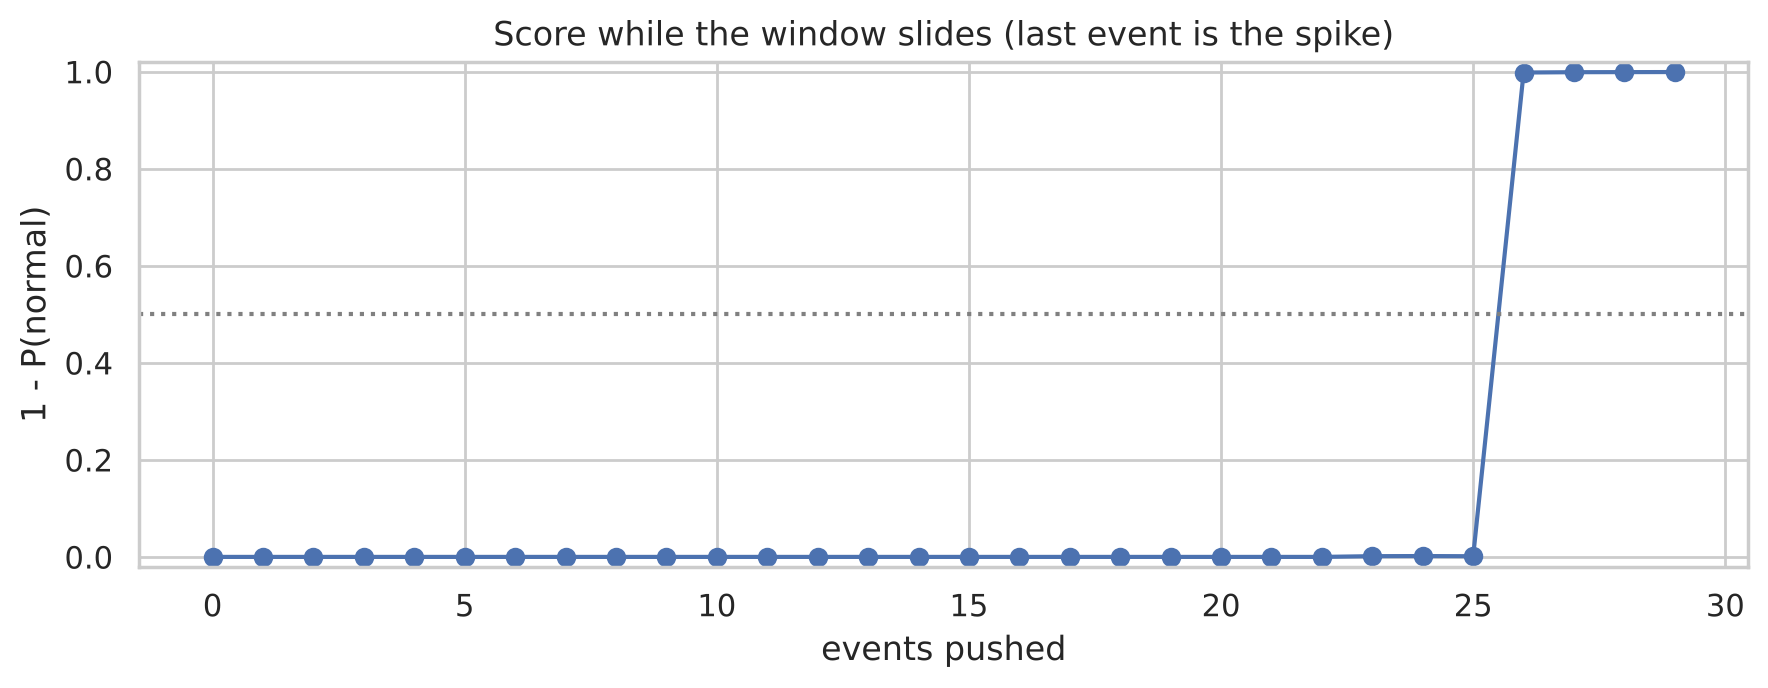

point score=0.999 {'normal': 0.001, 'point': 0.999, 'contextual': 0.0} top attention steps: [29, 28, 27]


In [12]:
i = int(np.flatnonzero((data.test.y == 1) & (pred == 1))[0])
detector.reset()
stamp = datetime(2026, 11, 21, tzinfo=UTC)
res = [detector.push("demo", row, stamp) for row in data.test.x[i]]
warm = [r for r in res if not r.details["warming_up"]]
print(f"{len(res) - len(warm)} warm-up results (score 0), then {len(warm)} scored events")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(range(len(res)), [r.score for r in res], "o-"); ax.axhline(0.5, color="grey", ls=":")
ax.set(title="Score while the window slides (last event is the spike)", xlabel="events pushed", ylabel="1 - P(normal)", ylim=(-0.02, 1.02))
plt.tight_layout(); plt.show()
last = res[-1]
print(last.anomaly_type, f"score={last.score:.3f}", {k: round(v, 3) for k, v in last.details["class_probabilities"].items()},
      "top attention steps:", last.details["top_attention_steps"])

## 9. Summary and recommendations

In [13]:
display(Markdown(f'''
| | |
|---|---|
| Macro-F1 (test, argmax) | **{rep.macro_f1:.3f}** |
| Point: precision / recall / F1 | {rep.precision[1]:.3f} / {rep.recall[1]:.3f} / {rep.f1[1]:.3f} |
| Contextual: precision / recall / F1 | {rep.precision[2]:.3f} / {rep.recall[2]:.3f} / {rep.f1[2]:.3f} |
| Contextual ROC-AUC (OvR) | {rep.roc_auc["contextual"]:.3f} |
| Any-anomaly ROC-AUC | {rep.anomaly_roc_auc:.3f} |
| Temperature | {T:.2f} (NLL {rep_raw.nll:.3f} -> {rep.nll:.3f}, ECE {rep_raw.ece:.3f} -> {rep.ece:.3f}) |
'''))


| | |
|---|---|
| Macro-F1 (test, argmax) | **0.815** |
| Point: precision / recall / F1 | 1.000 / 0.993 / 0.997 |
| Contextual: precision / recall / F1 | 0.452 / 0.472 / 0.462 |
| Contextual ROC-AUC (OvR) | 0.924 |
| Any-anomaly ROC-AUC | 0.952 |
| Temperature | 2.50 (NLL 0.151 -> 0.082, ECE 0.021 -> 0.005) |


**Reading the results**

* **Point anomalies are essentially solved**: a spike is a large, abrupt departure in the newest row and
  the one-vs-rest AUC is about 1.0. (Its attention is only mildly concentrated on the newest steps - the
  bidirectional LSTM has already moved the information into its outputs - whereas for contextual windows the
  attention sits almost entirely on the newest five steps; section 7.) This is the class the classifier adds
  most over the unsupervised detectors.
* **Contextual anomalies are separable but not cleanly classifiable.** The ranking quality (AUC) is high, but
  precision is low: most false alarms are normal windows shortly after a real anomaly, where the 5- and
  15-minute aggregates still carry the shifted level (section 5). That is a property of the labelling
  ("newest row") and the features, not of the optimiser; in a separate experiment, SMOTE ratios 0, 0.1 and 0.3
  gave contextual F1 of 0.39, 0.34 and 0.33, i.e. oversampling does not fix it.
* **Calibration**: temperature scaling fixes over-confidence (section 3) but cannot restore the natural base
  rate that SMOTE removed. Use the score for ranking and as an ensemble input, not as a literal probability.

**Next steps (not done here)**: add a "recently anomalous" feature or label the post-anomaly recovery rows
explicitly so the model can learn that state; train the full 50 epochs on more simulated hours; choose the
decision threshold on validation data (section 6); keep this model's output as one input of the Day 12
stacking meta-learner rather than as a stand-alone alarm.